In [13]:
import os
import re
import json

from dotenv import load_dotenv
from youtube_transcript_api import YouTubeTranscriptApi
from openai import OpenAI

import tiktoken
import pandas as pd

from IPython.display import display, Markdown


In [14]:
load_dotenv(override=True)

GEMINI_BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"

api_key = os.getenv("GOOGLE_API_KEY")

if not api_key:
    raise ValueError("No API Key was found.")

client = OpenAI(
    base_url=GEMINI_BASE_URL,
    api_key=api_key
)

MODEL = "gemini-3.6-flash"

print("Gemini client initialized!")

Gemini client initialized!


In [15]:
def extract_video_id(url):

    patterns = [
        r"(?:v=)([^&]+)",
        r"youtu\.be/([^?&]+)",
        r"shorts/([^?&]+)"        
    ]

    for pattern in patterns:
        match = re.search(pattern,url)

        if match:
            return match.group(1)

    raise ValueError("Invalid YouTube url")

In [16]:
url = "https://www.youtube.com/watch?v=49_Ph2q6uIM"

video_id = extract_video_id(url)

print(video_id)

49_Ph2q6uIM


In [17]:
def fetch_transcript(url):

    transcript_list = YouTubeTranscriptApi().fetch(video_id)
    transcript = []

    for snippet in transcript_list:
        transcript.append(snippet.text)

    return " ".join(transcript)

In [18]:
transcript = fetch_transcript(video_id)
print(transcript[:4000])

This morning, a machine screamed at you until you woke up. You silenced it, and from that second, your day was already decided. Where you had to be, what you had to finish, how many hours belong to someone else. And tonight, before you sleep, you'll set that same machine to scream at you again. Now, rewind 50,000 years. A man wakes up in the morning light with no alarm, no schedule, and nowhere he has to be. He owns a spear, two animal hides, and a fire. And he sits up, stretches, and asks himself a question you have never once been free enough to ask. What should I do today? Now, your brain is already fighting this. It's telling you no, ancient life was brutal, short, and desperate. Every second was survival. That's what everyone believed. For centuries, that was the official story. But the proof that it's wrong was lying buried in the ground the entire time. And when scientists finally dug it up, it flipped everything upside down. And that opens up a mystery. Because you live surroun

In [19]:
encoding = tiktoken.encoding_for_model("gpt-4.1-mini")

tokens = encoding.encode(transcript)

print("Characters:", len(transcript))
print("Words:", len(transcript.split()))
print("Tokens:", len(tokens))

Characters: 14094
Words: 2516
Tokens: 3009


In [20]:
def chunk_transcript(text, max_tokens=2000):
    tokens = encoding.encode(text)

    chunks = []

    for i in range(0, len(tokens), max_tokens):
        chunk_tokens = tokens[i:i + max_tokens]

        chunk_text = encoding.decode(chunk_tokens)
        chunks.append(chunk_text)

    return chunks

In [21]:
chunks = chunk_transcript(transcript)

print("Total chunks:", len(chunks))

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}: {len(encoding.encode(chunk))} tokens")

Total chunks: 2
Chunk 1: 2000 tokens
Chunk 2: 1009 tokens


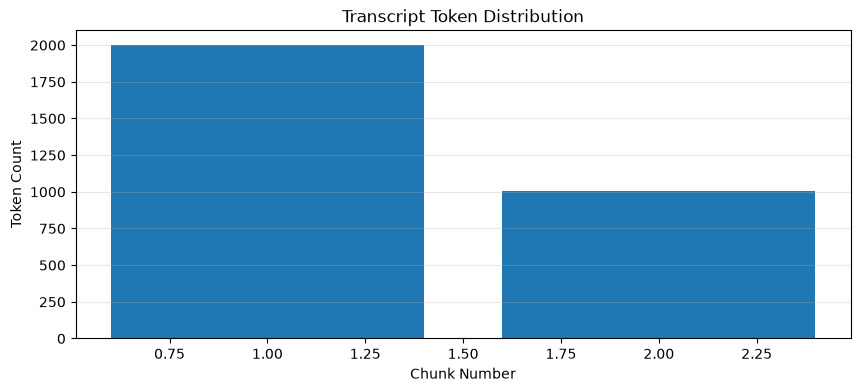

In [22]:
import matplotlib.pyplot as plt

chunk_sizes = [
    len(encoding.encode(chunk))
    for chunk in chunks
]

plt.figure(figsize=(10, 4))
plt.bar(range(1, len(chunk_sizes) + 1), chunk_sizes)

plt.title("Transcript Token Distribution")
plt.xlabel("Chunk Number")
plt.ylabel("Token Count")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [23]:
def summarize_chunk(chunk):

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": """
                You are an expert educational assistant.
                Summarize the provided video transcript.

                Focus on:
                - Main ideas
                - Important concepts
                - Key explanations
                - Practical examples

                Keep the summary concise but informative.
                Do not invent information.
                """
            },
            {
                "role": "user",
                "content": chunk
            }
        ]
    )

    return response.choices[0].message.content

In [24]:
chunk_summaries = []

for i, chunk in enumerate(chunks):
    print(f"Summarizing chunk {i+1}/{len(chunks)}...")

    summary = summarize_chunk(chunk)
    chunk_summaries.append(summary)

print("All chunks are summarized")

Summarizing chunk 1/2...
Summarizing chunk 2/2...
All chunks are summarized


In [25]:
def generate_final_summary(summaries):

    combined_summaries = "\n\n".join(summaries)

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": """
                You are an expert educational assistant.

                Combine the provided summaries into one
                comprehensive and well-structured summary.

                Remove repetition.
                Preserve important concepts.
                Organize information using headings and bullet points.
                Do not introduce unsupported information.
                """
            },
            {
                "role": "user",
                "content": combined_summaries
            }
        ]
    )

    return response.choices[0].message.content

In [26]:
final_summary = generate_final_summary(chunk_summaries)

display(Markdown(final_summary))

### **Overview**
Archaeological and anthropological evidence reveals that pre-agricultural hunter-gatherers were not locked in a constant, desperate struggle for survival. Instead, they enjoyed better health, lower workloads, and significantly more free time than both early agriculturalists and modern humans.

---

### **Hunter-Gatherer Workload and Daily Rhythm**

*   **Low Work Hours:** Pre-agricultural humans spent only about **15 to 20 hours per week** securing food—a fraction of the modern workweek. 
    *   In 1963, anthropologist Richard Lee documented the Ju/'hoansi people of the Kalahari Desert spending roughly 17 hours per week gathering food.
    *   Similar low-work patterns have been recorded across multiple continents, including the Hadza (Tanzania), the Ache (Paraguay), and the Martu (Australia).
*   **Persistence Hunting:** Rather than sprinting, hunters walked after game for extended periods. Because humans cool down by sweating while animals cannot, prey eventually collapsed from overheating. A single successful hunt provided food for days.
*   **Day vs. Night Conversation Dynamics:** A 2014 study by anthropologist Polly Wiessner analyzed Ju/'hoansi conversations, identifying a clear divide in daily focus:
    *   **Daytime:** Conversations focused strictly on practical logistics (water locations, plant gathering, tracking animals).
    *   **Nighttime:** Firelight allowed people to relax, shifting **81% of nighttime conversations** to storytelling, cultural expression, jokes, and ancestral myths.

---

### **Health, Culture, and Social Structure**

*   **Superior Physical Health:** Skeletons of hunter-gatherers reveal tall, thick, strong bones, clean joints, minimal tooth decay, and longer lifespans, reflecting varied physical movement and a well-balanced diet.
*   **Socializing as Insurance:** Lacking currency, courts, or institutional pensions, personal relationships served as a vital social safety net. Ju/'hoansi adults spent around **6 hours every day** socializing, grooming, and crafting, ensuring that others would care for and share food with them in times of injury, illness, or failed hunts.
*   **Art and Music:** Ample free time fostered early artistic and musical innovation:
    *   **Blombos Cave (South Africa):** 70,000-year-old shell beads gathered from distant locations were intricately drilled to be worn as jewelry.
    *   **Vulture-Bone Flute (Germany):** A 40,000-year-old flute featuring five finger holes indicates early humans had the leisure time to master musical scales, craft instruments, and practice playing.
*   **Biphasic Sleep:** Before artificial lighting existed, humans naturally slept in two distinct four-hour blocks divided by one to two hours of quiet wakefulness in the middle of the night. What is modernly categorized as insomnia was historically a standard sleep pattern for thousands of generations.

---

### **The Agricultural Shift and "The Trap"**

Around 10,000 years ago in the Fertile Crescent, humanity shifted from hunting and gathering to farming. Although farming generated larger quantities of food, it triggered a self-reinforcing population trap:

1. **Food Increase:** More crops allowed human populations to grow.
2. **Expansion:** Larger populations required clearing more fields and planting more crops.
3. **Increased Labor:** Expanded fields demanded vastly more manual effort (plowing, weeding, harvesting).
4. **Point of No Return:** Once populations reached a certain size, returning to a hunter-gatherer lifestyle became impossible.

#### **Physical Toll of Farming**
Compared to hunter-gatherers, early farmers experienced significantly worse health, including shorter lifespans, frequent cavities, and severe spine arthritis caused by thousands of hours of repetitive grinding and bending.

---

### **Societal Transformation and the Loss of Time Freedom**

*   **Emergence of Class Hierarchies:** Agricultural surpluses permitted the development of trade, cities, and specialized non-farming classes, such as soldiers, tax collectors, and priests.
*   **Monetization of Human Time:** For the first time, people had to trade their labor hours to others in exchange for food. 
*   **Modern vs. Ancestral Freedom:** Early humans maintained daily personal freedom from birth to death. By contrast, modern humans now spend approximately **90,000 hours** of their lives working while striving toward retirement.

In [27]:
notes_system_prompt = """
You are an expert educational note-taking assistant.

Create detailed study notes from the provided video summary.

Organize the notes into:

1. Main Topic
2. Important Concepts
3. Detailed Explanations
4. Examples
5. Key Takeaways

Instructions:
- Use clear and simple language.
- Use headings and bullet points.
- Preserve important technical terminology.
- Include examples when available.
- Do not invent information.
- Avoid unnecessary repetition.

Return the notes in Markdown.
"""

In [28]:
def generate_study_notes(summary):
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": notes_system_prompt
            },
            {
                "role": "user",
                "content": f"Create study notes from:\n\n{summary}"
            }
        ]
    )
    return response.choices[0].message.content

In [29]:
study_notes = generate_study_notes(final_summary)
display(Markdown(study_notes))

# Study Notes: Hunter-Gatherer Lifestyles vs. The Agricultural Shift

---

## 1. Main Topic
A comparative analysis of pre-agricultural hunter-gatherer societies, the transition to early agriculture, and modern human lifestyles—focusing on workload, physical health, social structures, and leisure time.

---

## 2. Important Concepts

*   **Persistence Hunting:** A hunting strategy where humans walked after game over long periods. Because humans cool down by sweating and animals do not, prey eventually collapsed from overheating.
*   **Biphasic Sleep:** A natural sleep pattern consisting of two 4-hour sleep blocks separated by 1 to 2 hours of quiet wakefulness in the middle of the night.
*   **Socializing as Insurance:** The practice of investing time in personal relationships, grooming, and shared activities to build a social safety net, ensuring care and shared resources during illness or failed hunts.
*   **The Agricultural Trap (Population Trap):** A self-reinforcing cycle where agricultural food surpluses caused population growth, requiring more land clearing and labor, ultimately preventing a return to hunter-gatherer life.

---

## 3. Detailed Explanations

### Hunter-Gatherer Workload and Daily Rhythm
*   **Low Work Hours:** Pre-agricultural humans worked significantly fewer hours than modern humans, averaging only **15 to 20 hours per week** securing food.
*   **Conversation Dynamics (Day vs. Night):**
    *   **Daytime:** Focused entirely on practical needs and logistics (locating water, gathering plants, tracking animals).
    *   **Nighttime:** Sitting around firelight allowed relaxation; **81% of night conversations** centered on storytelling, jokes, cultural traditions, and myths.

### Health and Physical Well-Being
*   **Hunter-Gatherers:** Skeletal evidence shows tall, thick, strong bones, clean joints, minimal tooth decay, and longer lifespans resulting from diverse physical movement and a balanced diet.
*   **Early Agriculturalists:** Farmers experienced declining health, shorter lifespans, frequent cavities, and severe spinal arthritis caused by repetitive bending and grinding manual labor.

### Social Structure, Art, and Leisure
*   **Built-in Safety Nets:** Lacking institutions, currency, or courts, adults spent approximately **6 hours per day** socializing and crafting to maintain communal bonds.
*   **Cultural Innovation:** Abundant free time permitted early humans to master musical scales, craft instruments, and produce personal jewelry.

### The Agricultural Shift and Societal Evolution
*   **Shift to Farming:** Occurred roughly 10,000 years ago in the Fertile Crescent.
*   **Emergence of Class Hierarchies:** Food surpluses enabled specialized non-farming roles to form (such as soldiers, tax collectors, and priests).
*   **Monetization of Time:** Farming established a system where individuals had to trade their labor hours for food, replacing personal lifelong day-to-day freedom with structured labor (averaging around 90,000 work hours over a modern lifespan).

---

## 4. Examples

*   **Documented Hunter-Gatherer Groups:**
    *   *Ju/'hoansi (Kalahari Desert):* Anthropologists documented them spending roughly 17 hours a week gathering food and about 6 hours a day socializing.
    *   *Other groups with low work hours:* The Hadza (Tanzania), the Ache (Paraguay), and the Martu (Australia).
*   **Day vs. Night Conversation Study:** Anthropologist Polly Wiessner's 2014 study of the Ju/'hoansi documented the shift from daytime logistics to 81% nighttime storytelling around fires.
*   **Art and Music Artifacts:**
    *   *Blombos Cave (South Africa):* 70,000-year-old intricately drilled shell beads gathered from distant locations, worn as jewelry.
    *   *Vulture-Bone Flute (Germany):* A 40,000-year-old flute featuring five finger holes, demonstrating early musical mastery and leisure time.

---

## 5. Key Takeaways

1. **Pre-agricultural life was not a constant struggle:** Hunter-gatherers had shorter workweeks (15–20 hours), superior skeletal health, and significantly more free time than early farmers and modern humans.
2. **Socializing was essential for survival:** Daily socializing (~6 hours) and nighttime storytelling acted as vital social insurance policies in the absence of formal institutions.
3. **Natural human sleep was biphasic:** Prior to artificial light, sleeping in two distinct 4-hour blocks with a midnight period of wakefulness was normal human biology, not insomnia.
4. **The Agricultural Revolution was a trap:** Although farming produced more food, it led to population explosions, harder repetitive physical labor, worse overall health, class division, and the modern monetization of human time.

In [30]:
concepts_prompt = """
You are an expert technical educator.

Extract the most important concepts from the provided content.

For each concept, provide:
- Concept name
- Simple explanation
- Why it matters
- Example, if available

Return valid JSON in this format:

{
    "concepts": [
        {
            "name": "Concept name",
            "explanation": "Simple explanation",
            "importance": "Why it matters",
            "example": "Example"
        }
    ]
}

Do not invent information.
"""

In [31]:
def extract_concepts(summary):

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": concepts_prompt
            },
            {
                "role": "user",
                "content": summary
            }
        ],
        response_format={"type": "json_object"}
    )

    return json.loads(response.choices[0].message.content)

In [32]:
concepts = extract_concepts(final_summary)

for concept in concepts["concepts"]:

    display(Markdown(f"""
### {concept['name']}

**Explanation:** {concept['explanation']}

**Why it matters:** {concept['importance']}

**Example:** {concept['example']}

---
"""))


### Low-Work Hunter-Gatherer Lifestyle

**Explanation:** Pre-agricultural humans secured all their food in roughly 15 to 20 hours per week, enjoying lower workloads than modern humans.

**Why it matters:** It challenges the misconception that early humans were locked in a desperate, endless struggle for survival.

**Example:** Anthropologist Richard Lee documented the Ju/'hoansi people spending about 17 hours per week gathering food.

---



### Persistence Hunting

**Explanation:** A hunting technique where humans steadily walk after prey over long periods until the animal collapses from overheating.

**Why it matters:** It leverages unique human cooling capabilities (sweating) to secure days of food from a single successful hunt without continuous sprinting.

**Example:** Hunters tracking game until the prey, unable to cool itself down, eventually collapses.

---



### Nighttime Conversation Dynamics

**Explanation:** A daily pattern where conversations shift from practical survival logistics during the day to creative storytelling, myths, and social bonding at night around a fire.

**Why it matters:** It illustrates how leisure time and firelight fostered early culture, art, humor, and social expression.

**Example:** Ju/'hoansi people shifting 81% of nighttime conversations to storytelling, jokes, and ancestral myths.

---



### Socializing as Insurance

**Explanation:** Spending several hours daily building personal relationships, grooming, and interacting with community members.

**Why it matters:** In the absence of currency, legal systems, or formal pensions, strong social relationships served as a safety net ensuring care during illness, injury, or food shortages.

**Example:** Ju/'hoansi adults spending around 6 hours every day socializing, grooming, and crafting.

---



### Biphasic Sleep

**Explanation:** A natural sleep pattern featuring two distinct four-hour blocks of sleep separated by one to two hours of quiet wakefulness at night.

**Why it matters:** It reveals that sleep patterns often labeled as modern insomnia were actually the standard ancestral norm before artificial lighting.

**Example:** Sleeping in two four-hour shifts separated by a middle-of-the-night period of quiet wakefulness.

---



### The Agricultural Population Trap

**Explanation:** A self-reinforcing cycle where farming produced more food, causing population growth, which required more labor and fields, making a return to hunter-gatherer life impossible.

**Why it matters:** It explains how humanity permanently transformed into a high-labor, class-stratified society despite farming causing worse individual health and longer work hours.

**Example:** The shift in the Fertile Crescent 10,000 years ago where expanded crops triggered population growth that trapped communities into farming.

---
